# LA2: NEON Surface-Water Nitrate Forecasting

**Assigned sites:** BIGC, BLDE, BLUE  
**Data product:** NEON Nitrate in Surface Water, DP1.20033.001  
**Target:** `surfWaterNitrateMean` aggregated into a 30-minute nitrate mean (µmol/L).  
**Forecast horizons:** 24 hours and 7 days ahead.

This notebook reads the original `NSW_15_minute` CSV files, filters the NEON quality flag, removes duplicate site/timestamp records, aggregates to 30-minute bins, builds lag/calendar predictors, implements three Spark ML models, compares them against simple baselines, and records model metrics and execution-time/scalability measurements.

**Forecast design:** each row is indexed by the end of a completed 30-minute interval. Only current and historical predictors are used. A target is kept only when an accepted measurement exists exactly 24 hours or 7 days later; no future labels are interpolated. The split is chronological by site, and training labels must also occur before the site's test cutoff.

**Important:** local pilot tables included in the PDF are labelled as reference results from a small scikit-learn run and are not Spark timings. Run this notebook to generate the authoritative PySpark MLlib metrics and timings for your machine.

## 1. Environment and project paths

Use a local Spark installation (PySpark 3.5+ recommended), pandas and matplotlib. Start Jupyter from the extracted person folder or adjust the root path in the first code cell.

In [1]:
from pathlib import Path
import time, math, json, os
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

PERSON = "Person1"
SITE_IDS = ['BIGC', 'BLDE', 'BLUE']

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "dataset" / "raw").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not find dataset/raw. Start Jupyter from the extracted person folder, "
        "or update PROJECT_ROOT to point at that folder."
    )

PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / "dataset" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
for folder in (OUTPUT_DIR, FIGURE_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder
    .appName(f"LA2_{PERSON}_NEON_Nitrate_Forecasting")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Project root:", PROJECT_ROOT)
print("Selected sites:", SITE_IDS)
print("Spark version:", spark.version)


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/24 22:24:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Project root: /home/vishnu/Downloads/BDA_LA2/person1
Selected sites: ['BIGC', 'BLDE', 'BLUE']
Spark version: 4.2.0


## 2. Load the original dataset and audit quality flags

Only files named `*NSW_15_minute*.csv` are used as measurement inputs. Other metadata files are included to document the source but are not model rows.

In [2]:
# Load only the original NEON NSW_15_minute measurement tables for the assigned sites.
site_paths = [str(RAW_DIR / site) for site in SITE_IDS]
raw = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "false")
    .option("recursiveFileLookup", "true")
    .option("pathGlobFilter", "*NSW_15_minute*.csv")
    .csv(site_paths)
    .withColumn("source_path", F.input_file_name())
    .withColumn("siteID", F.regexp_extract(F.col("source_path"), r"/raw/([A-Z]{4})/", 1))
)
raw_count = raw.count()
print(f"Original measurement rows loaded: {raw_count:,}")
raw.printSchema()
raw.show(5, truncate=False)

# Quality-flag audit BEFORE filtering. NEON defines finalQF=0 as pass and finalQF=1 as fail.
quality_audit = (
    raw.withColumn("finalQF_int", F.col("finalQF").cast("int"))
       .groupBy("siteID", "finalQF_int")
       .agg(F.count(F.lit(1)).alias("row_count"))
       .orderBy("siteID", "finalQF_int")
)
quality_audit_pd = quality_audit.toPandas()
quality_audit_pd.to_csv(TABLE_DIR / "quality_flag_audit.csv", index=False)
display(quality_audit_pd)


Original measurement rows loaded: 680,832
root
 |-- startDateTime: string (nullable = true)
 |-- endDateTime: string (nullable = true)
 |-- surfWaterNitrateMean: string (nullable = true)
 |-- surfWaterNitrateMinimum: string (nullable = true)
 |-- surfWaterNitrateMaximum: string (nullable = true)
 |-- surfWaterNitrateVariance: string (nullable = true)
 |-- surfWaterNitrateNumPts: string (nullable = true)
 |-- surfWaterNitrateExpUncert: string (nullable = true)
 |-- surfWaterNitrateStdErMean: string (nullable = true)
 |-- finalQF: string (nullable = true)
 |-- source_path: string (nullable = false)
 |-- siteID: string (nullable = false)

+--------------------+--------------------+--------------------+-----------------------+-----------------------+------------------------+----------------------+-------------------------+-------------------------+-------+----------------------------------------------------------------------------------------------------------------------------------------

/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
                                                                                

,siteID,finalQF_int,row_count
0,BIGC,0,150846
1,BIGC,1,83586
2,BLDE,0,174248
3,BLDE,1,60184
4,BLUE,0,135763
5,BLUE,1,76205


## 3. Preprocessing and 30-minute aggregation

NEON's nitrate product is published as 15-minute averages. This study creates 30-minute means from valid 15-minute observations. A 30-minute bin with one accepted source observation is retained and its `valid_15min_count` is kept as a completeness feature; this choice is auditable in the saved data.

In [3]:
# Parse timestamps and numeric fields. Keep nonnegative nitrate observations with finalQF=0.
parsed = (
    raw
    .withColumn("start_ts", F.to_timestamp("startDateTime"))
    .withColumn("end_ts", F.to_timestamp("endDateTime"))
    .withColumn("nitrate", F.col("surfWaterNitrateMean").cast("double"))
    .withColumn("nitrate_min_source", F.col("surfWaterNitrateMinimum").cast("double"))
    .withColumn("nitrate_max_source", F.col("surfWaterNitrateMaximum").cast("double"))
    .withColumn("expanded_uncertainty", F.col("surfWaterNitrateExpUncert").cast("double"))
    .withColumn("standard_error", F.col("surfWaterNitrateStdErMean").cast("double"))
    .withColumn("finalQF_int", F.col("finalQF").cast("int"))
)
quality_filtered = parsed.filter(
    (F.col("siteID").isin(SITE_IDS))
    & F.col("start_ts").isNotNull()
    & F.col("nitrate").isNotNull()
    & (F.col("nitrate") >= 0)
    & (F.col("finalQF_int") == 0)
)

# Remove duplicate site/timestamp rows after applying the quality rule so that a flagged duplicate
# cannot displace an accepted record. Retain one deterministic source path per site/timestamp.
dedup_window = Window.partitionBy("siteID", "start_ts").orderBy(F.col("source_path"))
clean_15m = (
    quality_filtered
    .withColumn("_duplicate_rank", F.row_number().over(dedup_window))
    .filter(F.col("_duplicate_rank") == 1)
    .drop("_duplicate_rank")
    .cache()
)
print(f"Accepted, deduplicated 15-minute observations: {clean_15m.count():,}")

# Aggregate 15-minute means into non-overlapping 30-minute bins. The timestamp used below is the
# END of each 30-minute bin, so a prediction made at time t uses only completed intervals <= t.
with_bins = clean_15m.withColumn("bin", F.window(F.col("start_ts"), "30 minutes"))
aggregated = (
    with_bins.groupBy("siteID", "bin")
    .agg(
        F.avg("nitrate").alias("nitrate_mean"),
        F.min("nitrate_min_source").alias("nitrate_min"),
        F.max("nitrate_max_source").alias("nitrate_max"),
        F.avg("expanded_uncertainty").alias("uncertainty_mean"),
        F.avg("standard_error").alias("std_error_mean"),
        F.count("nitrate").alias("valid_15min_count"),
    )
    .select("siteID", F.col("bin.end").alias("time"), "nitrate_mean", "nitrate_min",
            "nitrate_max", "uncertainty_mean", "std_error_mean", "valid_15min_count")
    .cache()
)
print(f"Available 30-minute intervals: {aggregated.count():,}")
aggregated.orderBy("siteID", "time").show(10, truncate=False)


Accepted, deduplicated 15-minute observations: 459,285


Available 30-minute intervals: 232,147
+------+-------------------+------------+-----------+-----------+----------------+--------------+-----------------+
|siteID|time               |nitrate_mean|nitrate_min|nitrate_max|uncertainty_mean|std_error_mean|valid_15min_count|
+------+-------------------+------------+-----------+-----------+----------------+--------------+-----------------+
|BIGC  |2019-01-29 19:00:00|2.05        |1.5        |2.6        |1.33            |0.03          |2                |
|BIGC  |2019-01-31 16:00:00|3.7         |3.6        |3.8        |1.33            |0.02          |1                |
|BIGC  |2019-01-31 16:30:00|3.7         |3.6        |3.8        |1.33            |0.015         |2                |
|BIGC  |2019-01-31 17:00:00|3.7         |3.6        |3.8        |1.33            |0.01          |2                |
|BIGC  |2019-01-31 17:30:00|3.7         |3.5        |3.8        |1.33            |0.025         |2                |
|BIGC  |2019-01-31 18:00:00|3.6  

## 4. Feature engineering and forecasting labels

Predictors include nitrate history at 30 minutes, 1 hour, 24 hours and 7 days; current 30-minute summary/uncertainty features; and cyclic hour-of-day / day-of-year features. Labels are exact-time future nitrate means at +24h and +7d.

In [4]:
# Time features use the end time of the completed 30-minute interval.
features_df = (
    aggregated
    .withColumn("hour_value", F.hour("time") + F.minute("time") / F.lit(60.0))
    .withColumn("doy_value", F.dayofyear("time"))
    .withColumn("hour_sin", F.sin(F.lit(2.0 * math.pi) * F.col("hour_value") / F.lit(24.0)))
    .withColumn("hour_cos", F.cos(F.lit(2.0 * math.pi) * F.col("hour_value") / F.lit(24.0)))
    .withColumn("doy_sin", F.sin(F.lit(2.0 * math.pi) * (F.col("doy_value") - F.lit(1.0)) / F.lit(365.25)))
    .withColumn("doy_cos", F.cos(F.lit(2.0 * math.pi) * (F.col("doy_value") - F.lit(1.0)) / F.lit(365.25)))
    .withColumn("month", F.month("time").cast("double"))
    .drop("hour_value", "doy_value")
)

# Exact-time joins are used for lag/target features. A label is created only when an accepted
# aggregate exists exactly 24 hours or 7 days later; no interpolation is used to invent targets.
base_values = aggregated.select("siteID", "time", "nitrate_mean")

def add_shift_column(left_df, minutes, new_name, target=False):
    if target:
        # A future row at t+h is shifted back to t, placing its value beside the forecast origin.
        shifted = base_values.select(
            "siteID",
            (F.col("time") - F.expr(f"INTERVAL {minutes} MINUTES")).alias("time"),
            F.col("nitrate_mean").alias(new_name),
        )
    else:
        # A past value at t-h is shifted forward to t, becoming a predictor for the current row.
        shifted = base_values.select(
            "siteID",
            (F.col("time") + F.expr(f"INTERVAL {minutes} MINUTES")).alias("time"),
            F.col("nitrate_mean").alias(new_name),
        )
    return left_df.join(shifted, on=["siteID", "time"], how="left")

for minutes, name in [(30, "lag_30m"), (60, "lag_1h"), (1440, "lag_24h"), (10080, "lag_7d")]:
    features_df = add_shift_column(features_df, minutes, name, target=False)
features_df = add_shift_column(features_df, 1440, "target_24h", target=True)
features_df = add_shift_column(features_df, 10080, "target_7d", target=True).cache()

FEATURE_COLS = [
    "nitrate_mean", "lag_30m", "lag_1h", "lag_24h", "lag_7d",
    "nitrate_min", "nitrate_max", "uncertainty_mean", "std_error_mean",
    "valid_15min_count", "hour_sin", "hour_cos", "doy_sin", "doy_cos", "month"
]
print("Feature rows:", f"{features_df.count():,}")
print("24-hour labels available:", f"{features_df.filter(F.col('target_24h').isNotNull()).count():,}")
print("7-day labels available:", f"{features_df.filter(F.col('target_7d').isNotNull()).count():,}")
features_df.select("siteID", "time", "nitrate_mean", "lag_24h", "lag_7d", "target_24h", "target_7d").orderBy("siteID", "time").show(10, truncate=False)

site_coverage = (
    aggregated.groupBy("siteID")
    .agg(
        F.count(F.lit(1)).alias("aggregated_30min_intervals"),
        F.min("time").alias("first_interval_end_utc"),
        F.max("time").alias("last_interval_end_utc"),
        F.avg("nitrate_mean").alias("mean_nitrate_uM"),
        F.expr("percentile_approx(nitrate_mean, 0.5)").alias("median_nitrate_uM"),
        F.min("nitrate_mean").alias("min_nitrate_uM"),
        F.max("nitrate_mean").alias("max_nitrate_uM"),
    ).orderBy("siteID")
)
site_coverage_pd = site_coverage.toPandas()
site_coverage_pd.to_csv(TABLE_DIR / "site_coverage.csv", index=False)
display(site_coverage_pd)


Feature rows: 232,147
24-hour labels available: 224,657
7-day labels available: 208,104
+------+-------------------+------------+-------+------+------------------+---------+
|siteID|time               |nitrate_mean|lag_24h|lag_7d|target_24h        |target_7d|
+------+-------------------+------------+-------+------+------------------+---------+
|BIGC  |2019-01-29 19:00:00|2.05        |NULL   |NULL  |NULL              |NULL     |
|BIGC  |2019-01-31 16:00:00|3.7         |NULL   |NULL  |3.6500000000000004|6.0      |
|BIGC  |2019-01-31 16:30:00|3.7         |NULL   |NULL  |3.7               |6.0      |
|BIGC  |2019-01-31 17:00:00|3.7         |NULL   |NULL  |3.6               |6.0      |
|BIGC  |2019-01-31 17:30:00|3.7         |NULL   |NULL  |3.6500000000000004|6.0      |
|BIGC  |2019-01-31 18:00:00|3.6         |NULL   |NULL  |3.6500000000000004|6.0      |
|BIGC  |2019-01-31 18:30:00|3.6         |NULL   |NULL  |3.6               |6.0      |
|BIGC  |2019-01-31 19:00:00|3.6         |NULL   |NUL

/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,siteID,aggregated_30min_intervals,first_interval_end_utc,last_interval_end_utc,mean_nitrate_uM,median_nitrate_uM,min_nitrate_uM,max_nitrate_uM
0,BIGC,75533,2019-01-29 19:00:00,2025-06-01,2.404572,1.85,0.0,95.1
1,BLDE,88043,2018-09-24 16:30:00,2025-06-01,7.071048,6.80,0.0,24.9
2,BLUE,68571,2018-09-26 18:00:00,2025-06-01,36.133002,36.70,0.0,73.0


## 5. Exploratory visualisation

The notebook writes site coverage, daily concentration trends and nitrate distribution plots under `outputs/figures/`.

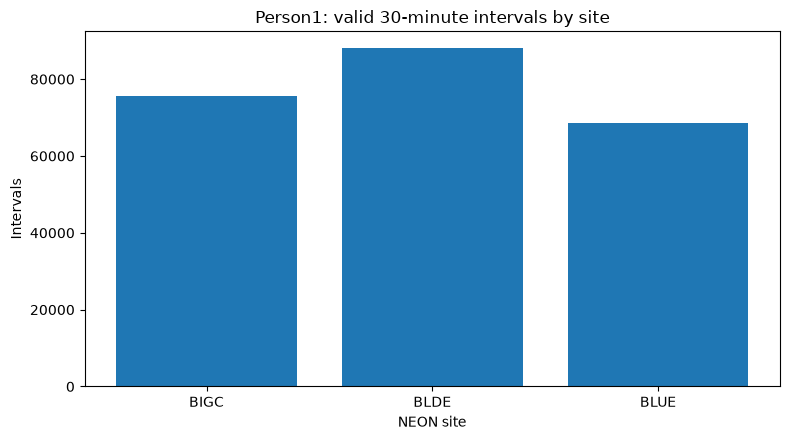

/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


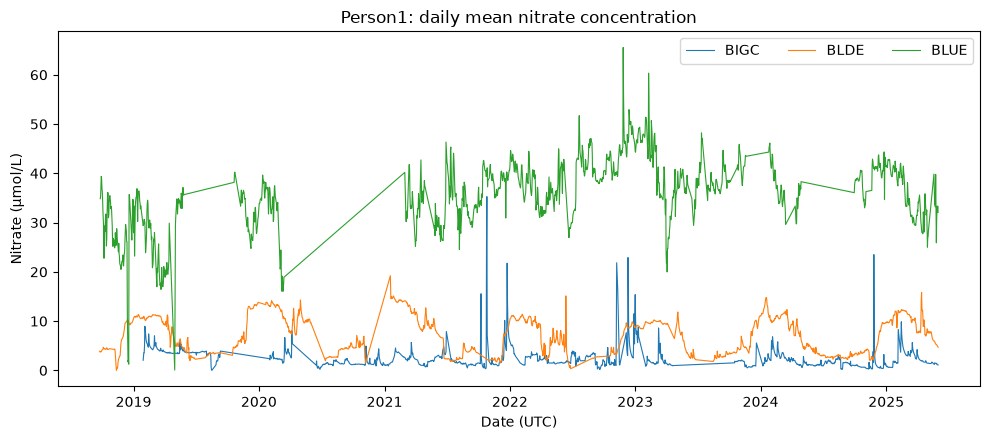

/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


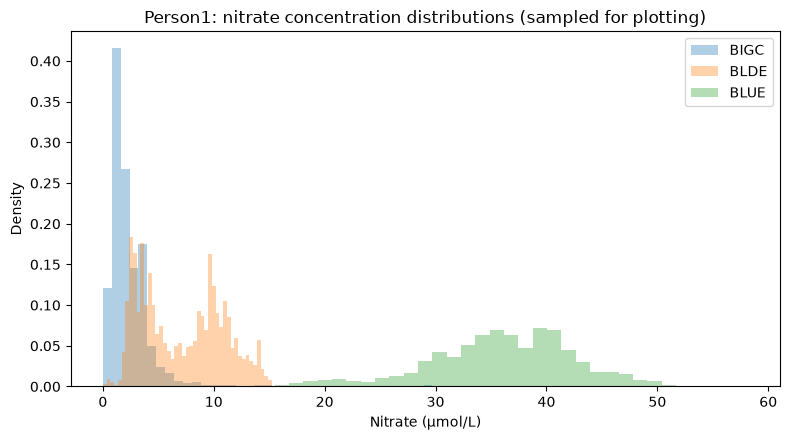

In [5]:
# Basic visualisations from the actual processed Spark dataset.
coverage_plot = site_coverage_pd.sort_values("siteID")
plt.figure(figsize=(8, 4.5))
plt.bar(coverage_plot["siteID"], coverage_plot["aggregated_30min_intervals"])
plt.title(f"{PERSON}: valid 30-minute intervals by site")
plt.xlabel("NEON site")
plt.ylabel("Intervals")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "site_coverage.png", dpi=150)
plt.show()

# Daily average plot, reduced to one row per site/day before collecting to the notebook process.
daily_pd = (
    aggregated.withColumn("date", F.to_date("time"))
    .groupBy("siteID", "date")
    .agg(F.avg("nitrate_mean").alias("daily_mean_nitrate_uM"))
    .orderBy("date")
    .toPandas()
)
plt.figure(figsize=(10, 4.5))
for site in SITE_IDS:
    d = daily_pd[daily_pd["siteID"] == site]
    plt.plot(pd.to_datetime(d["date"]), d["daily_mean_nitrate_uM"], label=site, linewidth=0.8)
plt.title(f"{PERSON}: daily mean nitrate concentration")
plt.xlabel("Date (UTC)")
plt.ylabel("Nitrate (µmol/L)")
plt.legend(ncol=3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "daily_nitrate_time_series.png", dpi=150)
plt.show()

hist_pd = aggregated.select("siteID", "nitrate_mean").sample(False, 0.04, seed=42).toPandas()
plt.figure(figsize=(8, 4.5))
for site in SITE_IDS:
    vals = hist_pd.loc[hist_pd["siteID"] == site, "nitrate_mean"].dropna()
    if len(vals):
        plt.hist(vals, bins=45, alpha=0.35, density=True, label=site)
plt.title(f"{PERSON}: nitrate concentration distributions (sampled for plotting)")
plt.xlabel("Nitrate (µmol/L)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "nitrate_distributions.png", dpi=150)
plt.show()


## 6. Model implementation and evaluation

Three Spark MLlib regressors are compared: Linear Regression, Random Forest Regressor and Gradient-Boosted Trees Regressor. The evaluation metrics are MAE, RMSE and R². Persistence and seasonal-naive baselines are included. Site-level error tables are required because the selected sites have different concentration ranges.

In [6]:
# A per-site chronological split. The training label must also fall before the cutoff so training
# never uses a future target that belongs to the held-out test period.
def make_horizon_split(frame, target_col, horizon_sql):
    labeled = (
        frame.filter(F.col(target_col).isNotNull())
        .withColumn("label", F.col(target_col).cast("double"))
        .withColumn("target_time", F.col("time") + F.expr(f"INTERVAL {horizon_sql}"))
    )
    order_w = Window.partitionBy("siteID").orderBy("time")
    count_w = Window.partitionBy("siteID")
    ranked = (
        labeled.withColumn("_rn", F.row_number().over(order_w))
        .withColumn("_n", F.count(F.lit(1)).over(count_w))
    )
    cutoff = ranked.groupBy("siteID").agg(
        F.max(F.when(F.col("_rn") <= F.floor(F.col("_n") * F.lit(0.80)), F.col("time"))).alias("cutoff_time")
    )
    split = ranked.join(cutoff, on="siteID", how="inner")
    helper_cols = ["_rn", "_n", "cutoff_time", "target_time"]
    train = split.filter((F.col("time") < F.col("cutoff_time")) & (F.col("target_time") < F.col("cutoff_time"))).drop(*helper_cols)
    test = split.filter(F.col("time") >= F.col("cutoff_time")).drop(*helper_cols)
    return train, test

NUMERIC_FEATURES = FEATURE_COLS
IMPUTED_FEATURES = [f"{c}_imputed" for c in NUMERIC_FEATURES]

def make_pipeline(model):
    imputer = Imputer(inputCols=NUMERIC_FEATURES, outputCols=IMPUTED_FEATURES, strategy="median")
    site_indexer = StringIndexer(inputCol="siteID", outputCol="site_index", handleInvalid="keep")
    site_encoder = OneHotEncoder(inputCols=["site_index"], outputCols=["site_vector"], handleInvalid="keep")
    assembler = VectorAssembler(inputCols=IMPUTED_FEATURES + ["site_vector"], outputCol="features", handleInvalid="keep")
    return Pipeline(stages=[site_indexer, site_encoder, imputer, assembler, model])

def metric_values(predictions):
    predictions = predictions.cache()
    n_rows = predictions.count()
    vals = {"n_test": int(n_rows)}
    for metric in ["rmse", "mae", "r2"]:
        evaluator = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=metric)
        vals[metric.upper()] = float(evaluator.evaluate(predictions))
    predictions.unpersist()
    return vals

model_rows = []
site_model_rows = []
models_by_horizon = {}

model_specs = [
    ("Linear Regression", lambda: LinearRegression(featuresCol="features", labelCol="label", maxIter=50, regParam=0.05)),
    ("Random Forest", lambda: RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=30, maxDepth=8, minInstancesPerNode=5, seed=42)),
    ("Gradient-Boosted Trees", lambda: GBTRegressor(featuresCol="features", labelCol="label", maxIter=20, maxDepth=4, stepSize=0.05, seed=42)),
]

for horizon, target_col, horizon_sql, seasonal_col in [
    ("24h", "target_24h", "1 DAY", "lag_24h"),
    ("7d", "target_7d", "7 DAYS", "lag_7d"),
]:
    train, test = make_horizon_split(features_df, target_col, horizon_sql)
    train = train.cache(); test = test.cache()
    n_train, n_test = train.count(), test.count()
    print(f"\nHorizon={horizon}: train={n_train:,}, test={n_test:,}")
    models_by_horizon[horizon] = {}

    for model_name, model_factory in model_specs:
        estimator = model_factory()
        pipeline = make_pipeline(estimator)
        start_fit = time.perf_counter()
        fitted = pipeline.fit(train)
        fit_seconds = time.perf_counter() - start_fit
        start_predict = time.perf_counter()
        predictions = fitted.transform(test).select("siteID", "time", "label", "prediction").cache()
        predictions.count()  # Force Spark's lazy transform before stopping the timer.
        predict_seconds = time.perf_counter() - start_predict
        metrics = metric_values(predictions)
        model_rows.append({"horizon": horizon, "model": model_name, "fit_seconds": fit_seconds,
                           "predict_seconds": predict_seconds, **metrics})

        # Site-level error is important because nitrate concentration scales differ substantially by site.
        means = predictions.groupBy("siteID").agg(F.avg("label").alias("site_label_mean"))
        per_site = (
            predictions.join(means, on="siteID", how="inner")
            .groupBy("siteID")
            .agg(
                F.count(F.lit(1)).alias("n_test"),
                F.avg(F.abs(F.col("label") - F.col("prediction"))).alias("MAE"),
                F.sqrt(F.avg(F.pow(F.col("label") - F.col("prediction"), 2))).alias("RMSE"),
                F.sum(F.pow(F.col("label") - F.col("prediction"), 2)).alias("SSE"),
                F.sum(F.pow(F.col("label") - F.col("site_label_mean"), 2)).alias("SST"),
            )
            .withColumn("R2", F.when(F.col("SST") > 0, 1.0 - F.col("SSE") / F.col("SST")))
            .withColumn("horizon", F.lit(horizon))
            .withColumn("model", F.lit(model_name))
        )
        site_model_rows.extend(per_site.toPandas().drop(columns=["SSE", "SST"]).to_dict("records"))
        models_by_horizon[horizon][model_name] = fitted
        predictions.unpersist()
        print(f"{model_name}: RMSE={metrics['RMSE']:.4f}, MAE={metrics['MAE']:.4f}, R2={metrics['R2']:.4f}, fit={fit_seconds:.2f}s")

    # Baseline 1: persistence (predict the current completed 30-minute mean).
    # Baseline 2: seasonal-naive (use the matching time-of-day nitrate mean from 24h / 7d earlier).
    for baseline_name, baseline_col in [("Persistence", "nitrate_mean"), ("Seasonal Naive", seasonal_col)]:
        baseline = test.filter(F.col(baseline_col).isNotNull()).withColumn("prediction", F.col(baseline_col))
        metrics = metric_values(baseline.select("siteID", "time", "label", "prediction"))
        model_rows.append({"horizon": horizon, "model": baseline_name, "fit_seconds": 0.0,
                           "predict_seconds": 0.0, **metrics})
        print(f"{baseline_name}: RMSE={metrics['RMSE']:.4f}, MAE={metrics['MAE']:.4f}, R2={metrics['R2']:.4f}")
    train.unpersist(); test.unpersist()

metrics_pd = pd.DataFrame(model_rows)
site_metrics_pd = pd.DataFrame(site_model_rows)
metrics_pd.to_csv(TABLE_DIR / "model_metrics_spark.csv", index=False)
site_metrics_pd.to_csv(TABLE_DIR / "site_model_metrics_spark.csv", index=False)
display(metrics_pd.sort_values(["horizon", "RMSE"]))
display(site_metrics_pd.sort_values(["siteID", "horizon", "RMSE"]))



Horizon=24h: train=179,577, test=44,936


26/10/24 22:25:15 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/10/24 22:25:22 WARN CacheManager: Asked to cache already cached data.        
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Linear Regression: RMSE=1.5695, MAE=0.6916, R2=0.9899, fit=11.41s


26/10/24 22:25:42 WARN DAGScheduler: Broadcasting large task binary with size 1367.0 KiB
26/10/24 22:25:46 WARN CacheManager: Asked to cache already cached data.        
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Random Forest: RMSE=1.6545, MAE=0.7256, R2=0.9888, fit=15.99s


...

Random Forest: RMSE=2.3082, MAE=1.3667, R2=0.9780, fit=13.41s


26/10/24 22:27:20 WARN CacheManager: Asked to cache already cached data.        
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Gradient-Boosted Trees: RMSE=2.7514, MAE=1.6435, R2=0.9687, fit=20.20s
Persistence: RMSE=2.4627, MAE=1.2868, R2=0.9749
Seasonal Naive: RMSE=2.6418, MAE=1.5170, R2=0.9691


,horizon,model,fit_seconds,predict_seconds,n_test,RMSE,MAE,R2
0,24h,Linear Regression,11.406531,1.455716,44936,1.569537,0.691553,0.989885
3,24h,Persistence,0.000000,0.000000,44936,1.611371,0.565333,0.989339
1,24h,Random Forest,15.987585,2.133759,44936,1.654528,0.725631,0.988760
2,24h,Gradient-Boosted Trees,20.884736,1.486178,44936,1.776507,0.962987,0.987041
4,24h,Seasonal Naive,0.000000,0.000000,43834,1.894782,0.796062,0.985228
5,7d,Linear Regression,6.297055,1.343579,41625,2.293959,1.354688,0.978229
6,7d,Random Forest,13.409450,1.658314,41625,2.308178,1.366655,0.977958
8,7d,Persistence,0.000000,0.000000,41625,2.462730,1.286825,0.974908
9,7d,Seasonal Naive,0.000000,0.000000,37993,2.641822,1.517016,0.969056
7,7d,Gradient-Boosted Trees,20.204582,1.295292,41625,2.751426,1.643481,0.968680


,siteID,n_test,MAE,RMSE,R2,horizon,model
1,BIGC,14574,0.512893,2.006893,0.070298,24h,Linear Regression
4,BIGC,14574,0.627439,2.137938,-0.055080,24h,Random Forest
7,BIGC,14574,0.854324,2.174940,-0.091917,24h,Gradient-Boosted Trees
13,BIGC,13301,0.998486,2.185998,-0.182484,7d,Random Forest
10,BIGC,13301,0.898821,2.382922,-0.405127,7d,Linear Regression
16,BIGC,13301,1.167481,2.396078,-0.420685,7d,Gradient-Boosted Trees
5,BLDE,17160,0.351885,0.585150,0.972755,24h,Random Forest
2,BLDE,17160,0.458984,0.645628,0.966832,24h,Linear Regression
8,BLDE,17160,0.737116,1.082187,0.906813,24h,Gradient-Boosted Trees
14,BLDE,16244,0.709597,1.101074,0.906400,7d,Random Forest


## 7. Execution-time and scalability analysis

The notebook measures fit/predict wall-clock seconds on the machine running Spark. The sampling benchmark uses 25%, 50% and 100% of a capped random 30,000-row pool, scoring up to 3,000 held-out rows. These timings are machine-specific and should be reported with the computer/Spark configuration.

Fraction=25%; train=7,620; fit=5.06s; predict=1.29s
Fraction=50%; train=15,041; fit=5.70s; predict=1.25s


Fraction=100%; train=29,993; fit=7.15s; predict=1.20s


,sample_fraction,training_rows,scoring_rows,fit_seconds,predict_seconds
0,0.25,7620,3000,5.063194,1.285712
1,0.50,15041,3000,5.703494,1.246826
2,1.00,29993,3000,7.149651,1.204154


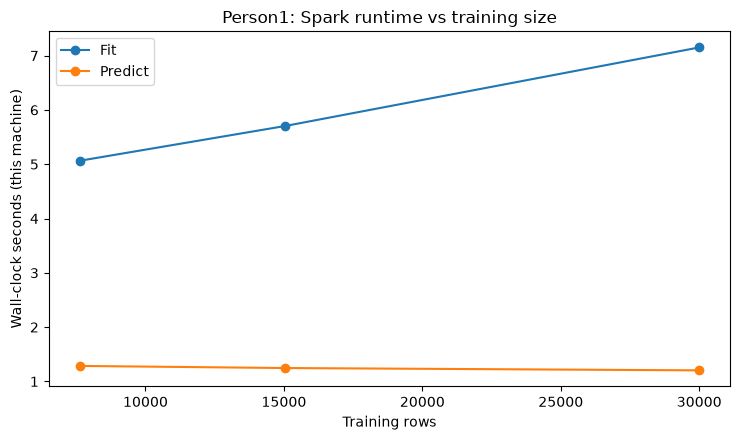

DataFrame[siteID: string, time: timestamp, nitrate_mean: double, nitrate_min: double, nitrate_max: double, uncertainty_mean: double, std_error_mean: double, valid_15min_count: bigint, hour_sin: double, hour_cos: double, doy_sin: double, doy_cos: double, month: double, lag_30m: double, lag_1h: double, lag_24h: double, lag_7d: double, target_24h: double, target_7d: double, label: double]

In [7]:
# Execution time and scalability benchmark. To keep this classroom experiment laptop-friendly,
# the scaling study caps its 24-hour training pool at 30,000 rows and evaluates 3,000 test rows.
train_24, test_24 = make_horizon_split(features_df, "target_24h", "1 DAY")
train_24 = train_24.cache(); test_24 = test_24.cache()
train_total = train_24.count()
cap_fraction = min(1.0, 30000.0 / max(train_total, 1))
scaling_cap = train_24.sample(withReplacement=False, fraction=cap_fraction, seed=4242).limit(30000).cache()
cap_n = scaling_cap.count()
scoring = test_24.limit(3000).cache()
scoring_count = scoring.count()
scaling_rows = []

for frac in [0.25, 0.50, 1.00]:
    sample = scaling_cap.sample(withReplacement=False, fraction=frac, seed=100 + int(frac * 100)).cache()
    sample_n = sample.count()
    if sample_n == 0:
        sample.unpersist()
        continue
    scale_model = RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=10, maxDepth=6, minInstancesPerNode=5, seed=42)
    scale_pipeline = make_pipeline(scale_model)
    t0 = time.perf_counter(); scale_fitted = scale_pipeline.fit(sample); fit_seconds = time.perf_counter() - t0
    t0 = time.perf_counter(); scale_predictions = scale_fitted.transform(scoring).select("prediction").cache(); scale_predictions.count(); predict_seconds = time.perf_counter() - t0
    scaling_rows.append({"sample_fraction": frac, "training_rows": int(sample_n), "scoring_rows": int(scoring_count),
                         "fit_seconds": fit_seconds, "predict_seconds": predict_seconds})
    print(f"Fraction={frac:.0%}; train={sample_n:,}; fit={fit_seconds:.2f}s; predict={predict_seconds:.2f}s")
    scale_predictions.unpersist(); sample.unpersist()

scaling_pd = pd.DataFrame(scaling_rows)
scaling_pd.to_csv(TABLE_DIR / "scalability_results_spark.csv", index=False)
display(scaling_pd)

plt.figure(figsize=(7.5, 4.5))
plt.plot(scaling_pd["training_rows"], scaling_pd["fit_seconds"], marker="o", label="Fit")
plt.plot(scaling_pd["training_rows"], scaling_pd["predict_seconds"], marker="o", label="Predict")
plt.title(f"{PERSON}: Spark runtime vs training size")
plt.xlabel("Training rows")
plt.ylabel("Wall-clock seconds (this machine)")
plt.legend(); plt.tight_layout()
plt.savefig(FIGURE_DIR / "runtime_scalability_spark.png", dpi=150)
plt.show()
train_24.unpersist(); test_24.unpersist(); scaling_cap.unpersist(); scoring.unpersist()


## 8. Outputs, interpretation and references

The notebook writes CSV tables and PNG figures to `outputs/`. Cite the official NEON product and quick-start guide, plus the Spark MLlib API documentation, in the final report. Treat pooled R² cautiously and discuss site-level errors and long-horizon uncertainty.

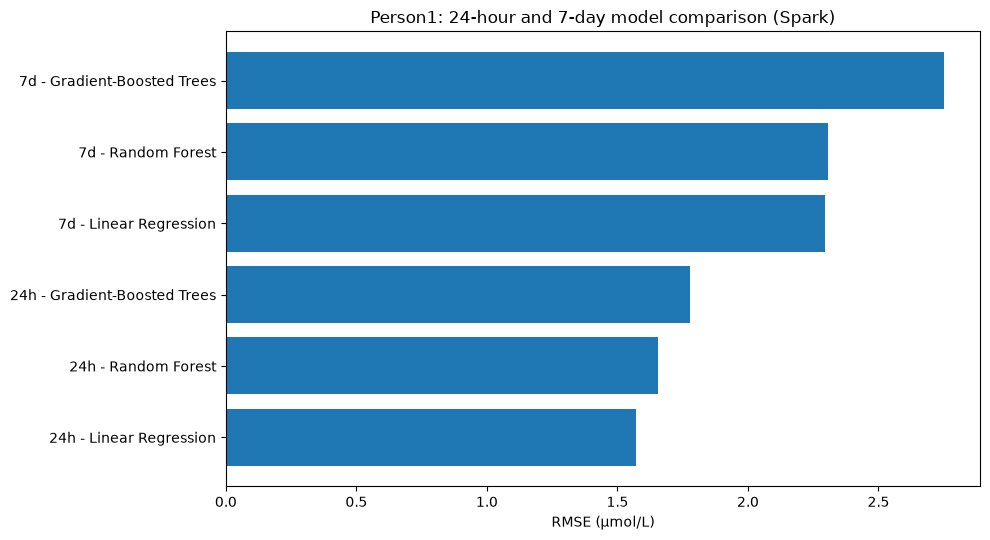

Outputs saved to: /home/vishnu/Downloads/BDA_LA2/person1/outputs
Tables: /home/vishnu/Downloads/BDA_LA2/person1/outputs/tables
Figures: /home/vishnu/Downloads/BDA_LA2/person1/outputs/figures
Important interpretation: report per-site MAE/RMSE as well as pooled metrics. A pooled R2 can look high when sites have very different nitrate concentration scales.


In [8]:
# Comparison plots are based on the Spark-generated result tables.
ml_metrics = metrics_pd[metrics_pd["model"].isin(["Linear Regression", "Random Forest", "Gradient-Boosted Trees"])].copy()
ml_metrics["label"] = ml_metrics["horizon"] + " - " + ml_metrics["model"]
plt.figure(figsize=(10, 5.5))
plt.barh(ml_metrics["label"], ml_metrics["RMSE"])
plt.xlabel("RMSE (µmol/L)")
plt.title(f"{PERSON}: 24-hour and 7-day model comparison (Spark)")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "model_rmse_comparison_spark.png", dpi=150); plt.show()

print("Outputs saved to:", OUTPUT_DIR)
print("Tables:", TABLE_DIR)
print("Figures:", FIGURE_DIR)
print("Important interpretation: report per-site MAE/RMSE as well as pooled metrics. A pooled R2 can look high when sites have very different nitrate concentration scales.")
